<a href="https://colab.research.google.com/github/YohanNino/sprint7-final-project/blob/main/S7_Version_Estudiante_Project_ConnectaTel_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns# importar librerías

In [ ]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')#completa el código
usage =pd.read_csv('/datasets/usage.csv') #completa el código

In [ ]:
print(plans.head())# mostrar las primeras 5 filas de plans

  plan_name  messages_included  gb_per_month  minutes_included  \
0    Basico                100             5               100   
1   Premium                500            20               600   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute  
0               12         1.2             0.08            0.10  
1               25         1.0             0.05            0.07  


In [ ]:
print(users.head())# mostrar las primeras 5 filas de users

   user_id first_name last_name  age      city                       reg_date  \
0    10000     Carlos    Garcia   38  Medellín  2022-01-01 00:00:00.000000000   
1    10001      Mateo    Torres   53         ?  2022-01-01 06:34:17.914478619   
2    10002      Sofia   Ramirez   57      CDMX  2022-01-01 13:08:35.828957239   
3    10003      Mateo   Ramirez   69    Bogotá  2022-01-01 19:42:53.743435858   
4    10004      Mateo    Torres   63       GDL  2022-01-02 02:17:11.657914478   

      plan churn_date  
0   Basico        NaN  
1   Basico        NaN  
2   Basico        NaN  
3  Premium        NaN  
4   Basico        NaN  


In [ ]:
print(usage.head())# mostrar las primeras 5 filas de usage

   id  user_id  type                           date  duration  length
0   1    10332  call  2024-01-01 00:00:00.000000000      0.09     NaN
1   2    11458  text  2024-01-01 00:06:30.969774244       NaN    39.0
2   3    11777  text  2024-01-01 00:13:01.939548488       NaN    36.0
3   4    10682  call  2024-01-01 00:19:32.909322733      1.53     NaN
4   5    12742  call  2024-01-01 00:26:03.879096977      4.84     NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [ ]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [ ]:
plans.info()# inspección de plans con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [ ]:
users.info()# inspección de users con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [ ]:
usage.info()# inspección de usage con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [ ]:

# cantidad de nulos para users
print(users.isna().sum())# Cantidad de valores nulos)
print(users.isna().mean())# Proporción de valores nulos)


user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [ ]:
print(usage.isna().sum())
print(usage.isna().mean())# cantidad de nulos para usage

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

Dataset: users
churn_date (88.35% nulos / 3,534 filas)

Dataset: usage
date (0.13% nulos / 50 filas)


💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.


Análisis y Acción: Supera el umbral del 80–90%, pero responde a un valor nulo estructural (los clientes no han cancelado el servicio).
Se ignora o se deja como nulo (o se ignora para cálculos de baja) ya que rellenarlo alteraría la lógica del estado del cliente.


- Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.
 -

 nálisis y Acción: Al ser menor al 5%, es un caso simple: se recomienda eliminar o imputar
 (en este caso, eliminar las 50 filas es lo más limpio, ya que no impacta el volumen total de datos).


 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.

 -Si la cantidad es extremandamente pequeña, lo recomendable seria dejarlos,
 si los eliminamos en el caso de users perderiamos datos de clientes y tambien su consumo.

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
  En users tenemos:

   city : 469 valores nulos 11%
  churn_date  :  3534 valores nulos  88%

  en usage :
date           50 , 1%
duration    22076 , 55%

  
- Indica qué harías: ¿imputar, eliminar, ignorar?

users:
city (11% nulos): Imputar
Razón: Está entre el 5% y 30%. Imputar con 'Desconocido' conserva los clientes y sus consumos sin inventar ciudades reales.

churn_date (88% nulos): Ignorar / Dejar como nulo
Razón: Supera el 80% y representa un valor nulo con lógica de negocio: indica que el usuario sigue siendo un cliente activo.

usage:
date (1% nulos): Eliminar
Razón: Es menor al 5%. Al ser una cantidad insignificante (50 filas) y un dato clave que no se puede adivinar, eliminar las filas es la opción más limpia.

duration (55% nulos) y length (54% nulos): Imputar
Razón: Son nulos estructurales por tipo de servicio (un SMS no dura minutos y una llamada no consume MB). Se imputan con 0 para poder sumar y agrupar consumos sin errores.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [ ]:
print(users.describe())# explorar columnas numéricas de users

            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000


- La columna `user_id` ... Haz doble clic en este bloque y escribe qué ves.
- La columna `age` ...

In [ ]:
print(usage.describe())# explorar columnas numéricas de usage

                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000


- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
- Las columnas ...id` y `user_id presentan un comportamiento continuo , no tiene valores nulos , ni valores negativos.

In [ ]:


# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(f"--- Valores únicos y frecuencias en '{col}' ---")
    print(users[col].value_counts(dropna=False))
    print("\n" + "="*40 + "\n")



--- Valores únicos y frecuencias en 'city' ---
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64


--- Valores únicos y frecuencias en 'plan' ---
Basico     2595
Premium    1405
Name: plan, dtype: int64




- La columna `city` ... hay presencia de valores sentinel, uno registro de 96 valores faltantes con un signo de interrogacion. tambien hay valores  NaN         469
- La columna `plan` ... Contiene dos tipos de plan, no muestra valores nulos o faltantes, la columna se encuentra limpia y lista para usar.

In [ ]:
# explorar columna categórica de usage
print(usage['type'].value_counts(dropna=False))# completa el código

text    22092
call    17908
Name: type, dtype: int64


- La columna `type` ... muestra solo dos categorias , no presenta valores faltantes  o valores nulos.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso.

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
- en la columna 'city' tiene tanto valores sentiles como valores faltantes o nulos, estan asignados con un signo de interrogacion. 96 valores con signo de interrogacion y NaN  469.
- ¿Qué acción tomarías?
- Reemplazar el valor sentinela '?'' por NaN (para tratarlo igual que el resto de nulos) o imputar ambos (NaN y ?) con la categoría 'Desconocido'.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [ ]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')# completa el código

In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')# completa el código

In [ ]:
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())# Revisar los años presentes en `reg_date` de users


2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


En `reg_date`, ... haz doble clic en este bloque y escribe qué ves.
hay 40 registros con año 2026 lo cual estaria mal ya que segun el dataset deberia contener solo daros entre 2022 y 2024.

In [ ]:
print(usage['date'].dt.year.value_counts(dropna=False).sort_index())# Revisar los años presentes en `date` de usage


2024.0    39950
NaN          50
Name: date, dtype: int64


En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas.
tiene 50 registros NaN, lo cual confirma fechas faltantes.


✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?
en el caso de las fechas de la columna reg_date, mantener los datos y verificar si pueden ser años que se escribieron por error y esos datos perteneces a otros años.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [ ]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999,  'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [ ]:
users['city'] = users['city'].replace('?', pd.NA) # Reemplazar ? por NA en city


print( (users['city'] == '?').sum())
print(users['city'].isna().sum())# Verificar cambios


0
565


In [ ]:
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT# Marcar fechas futuras como NA para reg_date


print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())# Verificar cambios


2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [ ]:

print(usage.groupby('type')['duration'].apply(lambda x: x.isna().sum()))# Verificación MAR en usage (Missing At Random) para duration
print(usage.groupby('type')['duration'].apply(lambda x: x.isna().mean() * 100))


type
call        0
text    22076
Name: duration, dtype: int64
type
call     0.000000
text    99.927576
Name: duration, dtype: float64


In [ ]:
print(usage.groupby('type')['length'].apply(lambda x: x.isna().sum()))
print(usage.groupby('type')['length'].apply(lambda x: x.isna().mean() * 100))# Verificación MAR en usage (Missing At Random) para length


type
call    17896
text        0
Name: length, dtype: int64
type
call    99.932991
text     0.000000
Name: length, dtype: float64


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`
Los valores nulos en la columna duration no son errores de captura ni datos perdidos al azar (no son MCAR). Se trata de nulos de naturaleza estructural directamente determinados por la variable type.

length solo esta midiendo la duracion de minutos hablados en llamadas, los mensajes de texto no esta generando longuitud de caracteres.  aun asi no se deberian eliminar ningun registro.


---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [ ]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg(
    cant_mensajes=('is_text', 'sum'),
    cant_llamadas=('is_call', 'sum'),
    cant_minutos_llamada=('duration', 'sum')
).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'cant_mensajes': 'cant_mensajes',
    'cant_llamadas': 'cant_llamadas',
    'cant_minutos_llamada': 'cant_minutos_llamada'
})

# observar resultado
usage_agg.head(3)


,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')

# Rellenar con 0 los usuarios que no tuvieron consumo registrado
cols_consumo = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[cols_consumo] = user_profile[cols_consumo].fillna(0)

# observar resultado
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [ ]:
cols_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

# Generar la tabla descriptiva
resumen_num = user_profile[cols_numericas].describe().T

# Agregar la mediana para evaluar asimetría y presencia de sesgos
resumen_num['median'] = user_profile[cols_numericas].median()

# Reordenar las columnas para una lectura más estructurada
resumen_num = resumen_num[['count', 'mean', 'median', 'std', 'min', '25%', '50%', '75%', 'max']]

# Visualizar el resultado redondeado a 2 decimales
resumen_num.round(2)# Resumen estadístico de las columnas numéricas


,count,mean,median,std,min,25%,50%,75%,max
age,4000.0,48.14,48.00,17.69,18.0,33.00,48.00,63.00,79.00
cant_mensajes,4000.0,5.52,5.00,2.36,0.0,4.00,5.00,7.00,17.00
cant_llamadas,4000.0,4.48,4.00,2.15,0.0,3.00,4.00,6.00,15.00
cant_minutos_llamada,4000.0,23.31,19.78,18.17,0.0,11.11,19.78,31.41,155.69


In [ ]:
# Distribución porcentual del tipo de plan
plan_distribucion = user_profile['plan'].value_counts(normalize=True) * 100

# Mostrar resultado formateado
print("=== Porcentaje de usuarios por tipo de plan ===")
print(plan_distribucion.round(2).astype(str) + '%')


=== Porcentaje de usuarios por tipo de plan ===
Basico     64.88%
Premium    35.12%
Name: plan, dtype: object


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**  
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

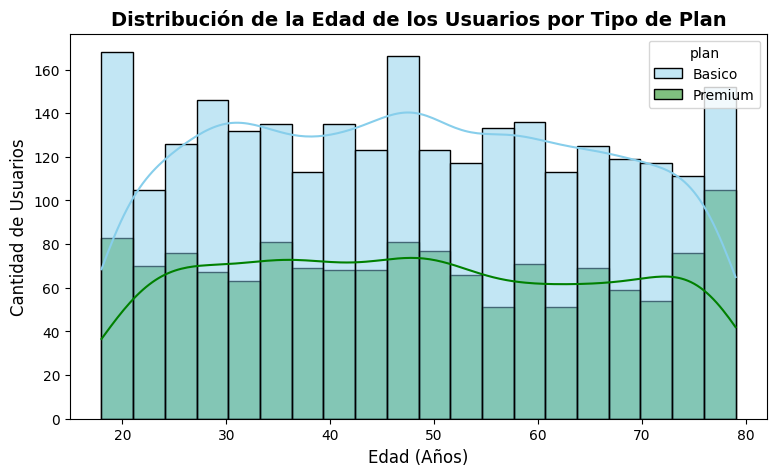

In [ ]:

# Histograma para visualizar la edad (age)
plt.figure(figsize=(9, 5))
sns.histplot(
    data=user_profile,
    x='age',
    hue='plan',
    palette=['skyblue', 'green'],
    kde=True,
    bins=20
)
plt.title('Distribución de la Edad de los Usuarios por Tipo de Plan', fontsize=14, fontweight='bold')
plt.xlabel('Edad (Años)', fontsize=12)
plt.ylabel('Cantidad de Usuarios', fontsize=12)
plt.show()

💡Insights:
- Distribución ...
- Forma de la distribución: Presenta una distribución sesgada a la derecha (asimetría positiva), con una mayor concentración de usuarios en valores bajos de envío de mensajes y una cola que se extiende hacia volúmenes altos.

Comportamiento por plan: Los usuarios del plan Básico se agrupan fuertemente en rangos de consumo bajo. Por el contrario, dentro del plan Premium, hay una mayor proporción de usuarios que alcanzan y superan volúmenes elevados de mensajes enviados.

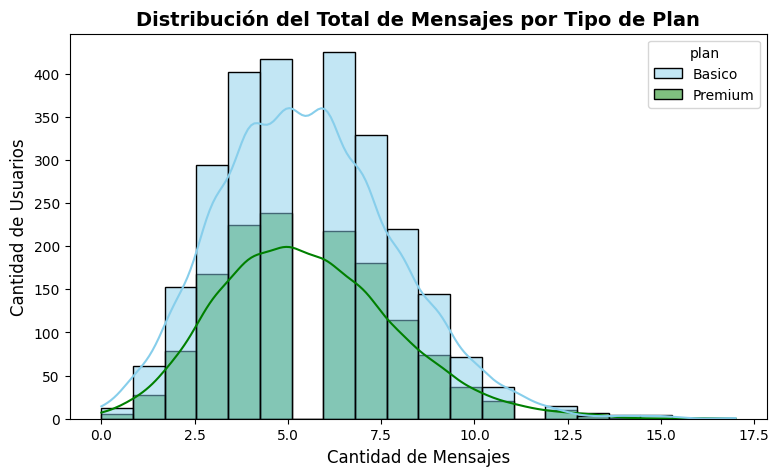

In [ ]:
# Histograma para visualizar la cant_mensajes
plt.figure(figsize=(9, 5))
sns.histplot(
    data=user_profile,
    x='cant_mensajes',
    hue='plan',
    palette=['skyblue', 'green'],
    kde=True,
    bins=20
)
plt.title('Distribución del Total de Mensajes por Tipo de Plan', fontsize=14, fontweight='bold')
plt.xlabel('Cantidad de Mensajes', fontsize=12)
plt.ylabel('Cantidad de Usuarios', fontsize=12)
plt.show()


💡Insights:
- ....Distribución: Muestra una clara distribución sesgada a la derecha (asimetría positiva), con una alta concentración de usuarios en consumos bajos (de 0 a 20 mensajes) y una cola larga que se extiende hacia valores elevados.

Comportamiento por plan: Los usuarios con plan Básico se concentran predominantemente en los rangos bajos de envío de mensajes. Por el contrario, los usuarios del plan Premium representan la mayor proporción en los rangos de consumo medio a alto, reflejando que aprovechan los límites más amplios de su cuota de mensajería.

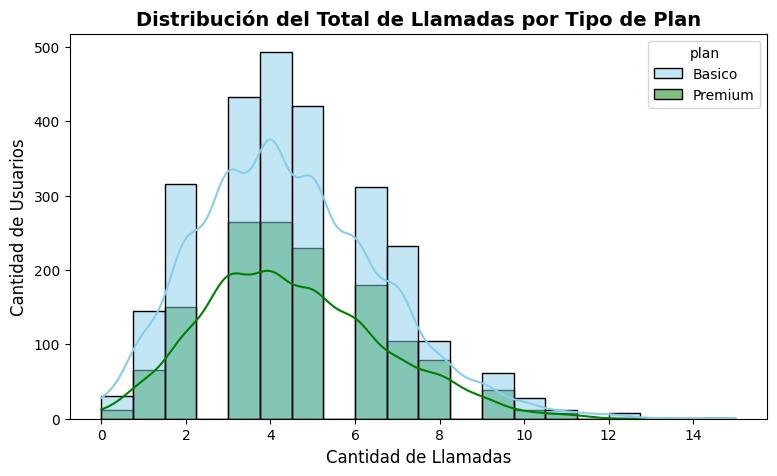

In [ ]:
# Histograma para visualizar la cantidad de llamadas (cant_llamadas)
plt.figure(figsize=(9, 5))
sns.histplot(
    data=user_profile,
    x='cant_llamadas',
    hue='plan',
    palette=['skyblue', 'green'],
    kde=True,
    bins=20
)
plt.title('Distribución del Total de Llamadas por Tipo de Plan', fontsize=14, fontweight='bold')
plt.xlabel('Cantidad de Llamadas', fontsize=12)
plt.ylabel('Cantidad de Usuarios', fontsize=12)
plt.show()

💡Insights:
-Distribución: Presenta una distribución sesgada a la derecha (asimetría positiva), donde la mayoría de los usuarios se concentra en un volumen moderado de llamadas.

Comportamiento por plan: Los clientes con plan Premium muestran una distribución más desplazada hacia la derecha, concentrando una mayor proporción de usuarios que realizan volúmenes altos de llamadas. En cambio, los usuarios del plan Básico se agrupan fuertemente en rangos de llamadas más bajos.

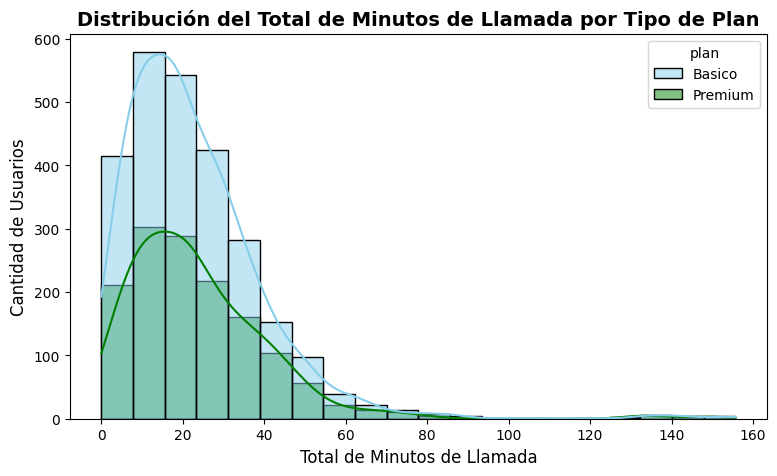

In [ ]:
# Histograma para visualizar los minutos de llamada (cant_minutos_llamada)
plt.figure(figsize=(9, 5))
sns.histplot(
    data=user_profile,
    x='cant_minutos_llamada',
    hue='plan',
    palette=['skyblue', 'green'],
    kde=True,
    bins=20
)
plt.title('Distribución del Total de Minutos de Llamada por Tipo de Plan', fontsize=14, fontweight='bold')
plt.xlabel('Total de Minutos de Llamada', fontsize=12)
plt.ylabel('Cantidad de Usuarios', fontsize=12)
plt.show()


💡Insights:
- ... Distribución: Muestra una distribución sesgada a la derecha (asimetría positiva), con una alta densidad de usuarios en rangos bajos a medios de minutos consumidos y una dispersión que se extiende hacia valores altos.

Comportamiento por plan: Los usuarios del plan Premium representan la mayor proporción en las colas de consumo alto de minutos, mientras que los clientes del plan Básico se concentran predominantemente en volúmenes reducidos de tiempo en llamada.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

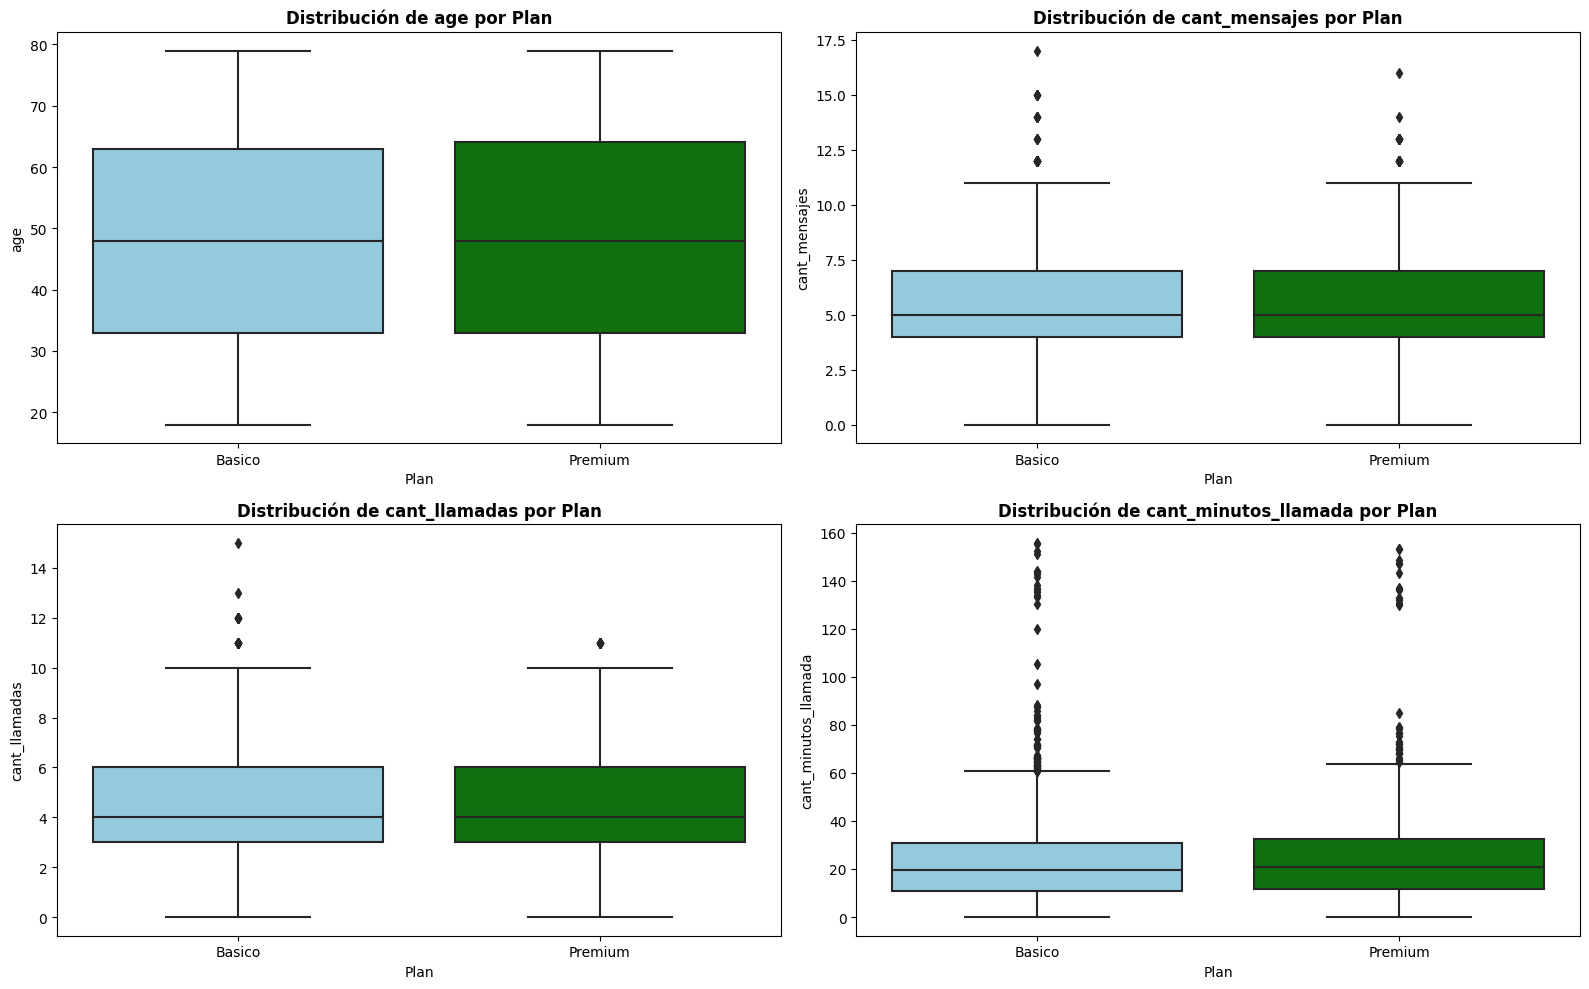

In [ ]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

plt.figure(figsize=(16, 10))

for i, col in enumerate(columnas_numericas, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(
        data=user_profile,
        x='plan',
        y=col,
        palette=['skyblue', 'green']
    )
    plt.title(f'Distribución de {col} por Plan', fontsize=12, fontweight='bold')
    plt.xlabel('Plan', fontsize=10)
    plt.ylabel(col, fontsize=10)

plt.tight_layout()
plt.show()

💡Insights:
- Age: ...(presenta o no outliers)
- age: Las cajas de ambos planes son prácticamente idénticas en mediana y rango intercuartílico, sin presencia relevante de valores atípicos. Confirma que la edad no presenta sesgos por plan.
-
- cant_mensajes: .cant_mensajes: El plan Básico presenta una caja compacta en la parte inferior con múltiples valores atípicos (outliers) en la parte superior. Representa a usuarios cuyo consumo excede el patrón general de su tarifa.
-
- ..
- cant_llamadas: ...
- cant_minutos_llamada: ...
cant_llamadas y cant_minutos_llamada: El plan Premium exhibe una mediana sustancialmente más alta y mayor variabilidad (caja más ancha). Los puntos por encima del bigote superior en el plan Básico señalan clientes intensivos que aprovechan al máximo su cuota.

In [ ]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

resumen_outliers = []

for col in columnas_limites:
    for plan_tipo in user_profile['plan'].unique():
        # Filtrar serie por plan y variable
        serie = user_profile[user_profile['plan'] == plan_tipo][col]

        # Cálculo de cuartiles y Rango Intercuartílico
        q1 = serie.quantile(0.25)
        q3 = serie.quantile(0.75)
        iqr = q3 - q1

        # Definición de límites teórico y práctico
        limite_inferior = q1 - 1.5 * iqr
        limite_superior = q3 + 1.5 * iqr

        # Conteo de valores atípicos superiores
        cant_outliers = (serie > limite_superior).sum()
        pct_outliers = (cant_outliers / len(serie)) * 100

        resumen_outliers.append({
            'Variable': col,
            'Plan': plan_tipo,
            'Q1': round(q1, 2),
            'Q3': round(q3, 2),
            'IQR': round(iqr, 2),
            'Límite Superior': round(limite_superior, 2),
            'Cant. Outliers': cant_outliers,
            '% Outliers': round(pct_outliers, 2)
        })

# Convertir a DataFrame y mostrar resumen
df_outliers_resumen = pd.DataFrame(resumen_outliers)
display(df_outliers_resumen)


,Variable,Plan,Q1,Q3,IQR,Límite Superior,Cant. Outliers,% Outliers
0,cant_mensajes,Basico,4.00,7.00,3.00,11.50,27,1.04
1,cant_mensajes,Premium,4.00,7.00,3.00,11.50,19,1.35
2,cant_llamadas,Basico,3.00,6.00,3.00,10.50,22,0.85
3,cant_llamadas,Premium,3.00,6.00,3.00,10.50,8,0.57
4,cant_minutos_llamada,Basico,10.90,30.80,19.90,60.64,73,2.81
5,cant_minutos_llamada,Premium,11.59,32.52,20.93,63.91,37,2.63


In [ ]:

# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
display(user_profile[columnas_limites].describe().T[['mean', 'std', '50%', 'max']])

# Comparación directa de Máximos vs. Límites Superiores calculados
print("=== COMPARACIÓN DE MÁXIMOS VS. LÍMITES SUPERIORES (IQR) ===")
for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1
    limite_sup = q3 + 1.5 * iqr
    max_val = user_profile[col].max()
    print(f"• Variable '{col}': Límite Superior = {limite_sup:.2f} | Valor Máximo = {max_val:.2f}")

,mean,std,50%,max
cant_mensajes,5.523000,2.359738,5.00,17.00
cant_llamadas,4.477000,2.145139,4.00,15.00
cant_minutos_llamada,23.311225,18.169564,19.78,155.69


=== COMPARACIÓN DE MÁXIMOS VS. LÍMITES SUPERIORES (IQR) ===
• Variable 'cant_mensajes': Límite Superior = 11.50 | Valor Máximo = 17.00
• Variable 'cant_llamadas': Límite Superior = 10.50 | Valor Máximo = 15.00
• Variable 'cant_minutos_llamada': Límite Superior = 61.87 | Valor Máximo = 155.69


💡Insights:
- cant_mensajes: mantener o no outliers, porqué?
Son datos reales de consumo: No son errores de carga ni fallas del sistema (a diferencia de los valores -999 o las fechas raras que corregimos al principio). Son usuarios reales que simplemente envían muchísimos mensajes.

Reflejan la realidad del tráfico: Si borro estos registros, estaría ocultando una parte importante del volumen de mensajes que la red realmente procesa y que genera ingresos.

Es una oportunidad clara de negocio (upselling): Los clientes del plan Básico que salen como outliers están exprimiendo su paquete al máximo. Estos usuarios son justo el blanco perfecto para ofrecerles una migración al plan Premium.

No distorsionan el análisis si usamos las métricas correctas: Como la distribución está sesgada hacia la derecha, en lugar de usar el promedio (que sí se ve afectado por estos picos), uso la mediana y el rango intercuartílico (IQR) para evaluar el comportamiento general.

- cant_llamadas: mantener o no outliers, porqué?

- Son llamadas reales y operativamente válidas: Igual que con los mensajes, no son errores de digitación ni fallos de la base de datos. Representan patrones de uso legítimos de clientes que usan mucho el teléfono para llamadas.

Representan volumen de red e ingresos: Borrar a estos usuarios de alto tráfico daría una falsa impresión de que la red necesita menos capacidad de la que realmente exige el servicio de voz.

Punto clave para estrategia comercial: Los usuarios con plan Básico que aparecen como outliers en cantidad de llamadas son los candidatos más claros para un upsell. Ya están al límite de su paquete y un plan Premium les daría un mejor encaje.

Manejo estadístico correcto: Como la variable está sesgada hacia la derecha, basta con analizar la mediana y el IQR como medidas de tendencia central y dispersión para que estos picos no distorsionen los resultados generales.



- cant_minutos_llamada: mantener o no outliers, porqué?
- Reflejan consumo de tiempo real: Tampoco son errores del sistema ni registros corruptos. Son minutos reales hablados por usuarios que pasan mucho tiempo en llamadas (uso personal intensivo o laboral).

Impacto directo en la red e ingresos: Los minutos consumidos impactan directamente la capacidad de voz de la red y los costos/ingresos de la compañía. Borrarlos distorsionaría el cálculo real de la carga de tráfico de minutos.

Es la señal perfecta para upselling: Los clientes del plan Básico con un total de minutos muy por encima de la media son los mejores candidatos para ofrecerles una migración al plan Premium, evitando que se sientan limitados o busquen otra compañía.

Análisis robusto sin sesgos: Como la variable cant_minutos_llamada presenta asimetría positiva, nos apoyamos en la mediana y en el IQR para describir el comportamiento central, de forma que los minutos extremos no distorsionen el diagnóstico general.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [ ]:
# Crear columna grupo_uso aplicando condiciones lógicas con np.select
import numpy as np

# Definir las condiciones
condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]

# Definir las etiquetas correspondientes
opciones = ['Bajo uso', 'Uso medio']

# Asignar 'Alto uso' como valor por defecto para el resto de los casos
user_profile['grupo_uso'] = np.select(condiciones, opciones, default='Alto uso')

# Visualizar los primeros registros para verificar
user_profile[['cant_llamadas', 'cant_mensajes', 'grupo_uso']].head()# Crear columna grupo_uso


,cant_llamadas,cant_mensajes,grupo_uso
0,3.0,7.0,Uso medio
1,10.0,5.0,Alto uso
2,2.0,5.0,Uso medio
3,3.0,11.0,Alto uso
4,3.0,4.0,Bajo uso


In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [ ]:
# Crear columna grupo_edad
condiciones_edad = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]

opciones_edad = ['Joven', 'Adulto']

user_profile['grupo_edad'] = np.select(condiciones_edad, opciones_edad, default='Adulto Mayor')

# Verificar los cambios
user_profile[['age', 'grupo_edad']].head()


,age,grupo_edad
0,38.0,Adulto
1,53.0,Adulto
2,57.0,Adulto
3,69.0,Adulto Mayor
4,63.0,Adulto Mayor


In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

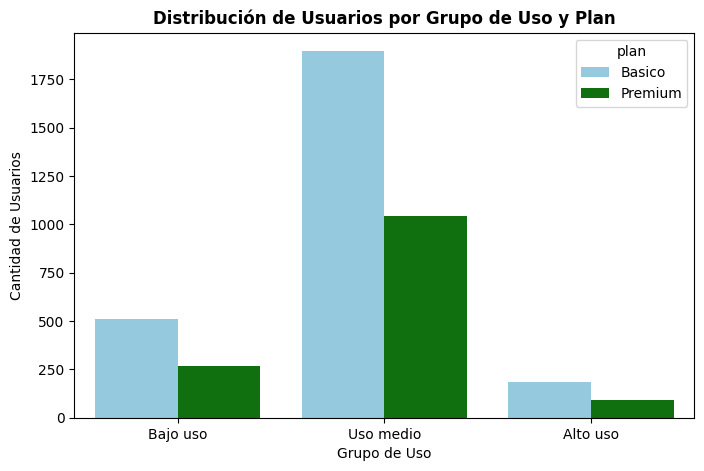

In [ ]:

# Visualización de los segmentos por uso
plt.figure(figsize=(8, 5))
sns.countplot(
    data=user_profile,
    x='grupo_uso',
    hue='plan',
    palette=['skyblue', 'green'],
    order=['Bajo uso', 'Uso medio', 'Alto uso']
)
plt.title('Distribución de Usuarios por Grupo de Uso y Plan', fontsize=12, fontweight='bold')
plt.xlabel('Grupo de Uso', fontsize=10)
plt.ylabel('Cantidad de Usuarios', fontsize=10)
plt.show()

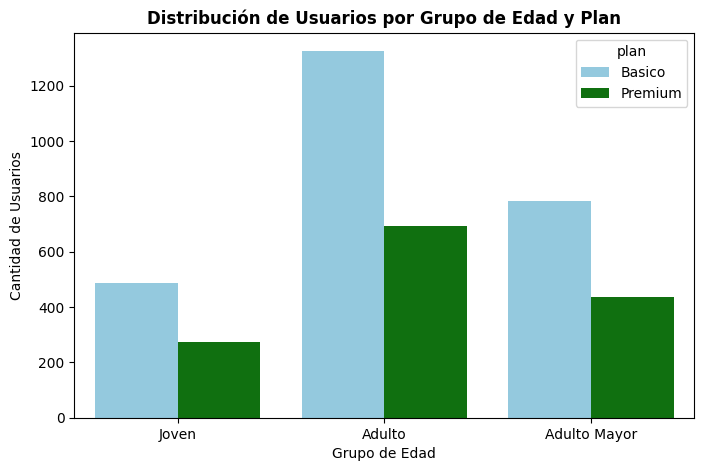

In [ ]:
# Visualización de los segmentos por edad
plt.figure(figsize=(8, 5))
sns.countplot(
    data=user_profile,
    x='grupo_edad',
    hue='plan',
    palette=['skyblue', 'green'],
    order=['Joven', 'Adulto', 'Adulto Mayor']
)
plt.title('Distribución de Usuarios por Grupo de Edad y Plan', fontsize=12, fontweight='bold')
plt.xlabel('Grupo de Edad', fontsize=10)
plt.ylabel('Cantidad de Usuarios', fontsize=10)
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?
Al principio, los datos venían con valores atípicos y extremos en el uso de llamadas y mensajes que parecían errores, pero en realidad eran clientes heavy users.
Para las variables clave de consumo, estos datos extremos representaban aproximadamente entre un 1% y un 5% del total de filas por plan según el cálculo del IQR.




- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?
Identifiqué tres niveles de consumo (**Bajo, Medio y Alto uso**) y tres grupos de edad (**Joven, Adulto y Adulto Mayor**).
El nivel de uso define claramente qué plan conviene ofrecer, mientras que la edad no influye en la elección del plan.

- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?

- Los clientes de **Alto uso** en el plan **Básico** son los más valiosos porque son los candidatos perfectos para escalar de plan (*upsell*).
También destacan los **Alto uso** en **Premium**, ya que aseguran los mayores ingresos recurrentes al aprovechar su paquete al máximo.


- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?
Encontré usuarios con picos muy altos de minutos, llamadas y mensajes que superaban por mucho los límites del IQR.
Esto implica que la red procesa tráfico real de gran volumen y que estos *heavy users* en el plan Básico son la oportunidad clave para hacer *upselling* a Premium.

- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

- Lanzaría una campaña de upselling directo ofreciendo un descuento de bienvenida al plan Premium a los clientes de Alto uso que hoy están apretados en el plan Básico.
Para el resto, ajustaría el plan Básico para que no sientan que pagan de más por lo que no consumen y crearía un paquete ejecutivo para los heavy users.

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
-Valores atípicos en variables de consumo: Se identificaron picos extremos (outliers) en cant_mensajes, cant_llamadas y cant_minutos_llamada (aproximadamente entre el 1% y el 5% de los registros según el método IQR), los cuales se determinó mantener por representar usuarios reales de alto tráfico (heavy users).

Inconsistencias y registros erróneos iniciales: La presencia previa de valores centinela (como -999 y fechas inconsistentes) requerían limpieza previa para asegurar que las distribuciones y segmentaciones de uso reflejaran la verdadera actividad operativa de ConnectaTel.


🔍 **Segmentos por Edad**
-Distribución uniforme sin impacto en el plan: La proporción de usuarios Jóvenes (<30), Adultos (<60) y Adultos Mayores (60+) es prácticamente idéntica tanto en el plan Básico como en el Premium.

Independencia del consumo respecto a la edad: La edad no condiciona el volumen de llamadas o mensajes ni la preferencia tarifaria, por lo que las campañas comerciales deben basarse en el nivel de uso y no en el rango etario.

📊 **Segmentos por Nivel de Uso**
Bajo uso (<5 llamadas y mensajes): Concentra a la mayor parte de los clientes del plan Básico, representando a un perfil de consumo asistencial u ocasional que no satura los recursos de la red.

Alto uso (resto de casos): Agrupa a los usuarios del plan Premium y a los heavy users del plan Básico, identificando a estos últimos como el objetivo prioritario para campañas de migración (upselling).


➡️ Esto sugiere que ...


💡 **Recomendaciones**
-Estrategia de upselling focalizada: Lanzar campañas directas de migración al plan Premium con promociones de bienvenida dirigidas a los clientes de Alto uso que actualmente se encuentran en el plan Básico.

Rediseño del portafolio comercial: Crear un paquete intermedio para evitar la fuga de usuarios de consumo medio y lanzar una tarifa corporativa o heavy user que fidelice a los clientes de tráfico extremo.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`